# 🦷 Oral Diseases Image Classification
### Fast 10-Minute Edition — Custom CNN vs. Pretrained Models, Tuning, Fine-Tuning, Comparison and Gradio Deployment

**Objective:** build, compare and deploy an AI system that classifies oral disease images into their correct categories.

| # | Requirement | Section |
|---|-------------|---------|
| 1 | Custom CNN | 8 |
| 2 | 3 pretrained models (EfficientNetB0, ResNet50V2, DenseNet121) | 9 – 11 |
| 3 | Hyperparameter tuning (Keras Tuner) | 7.4 |
| 4 | Data augmentation | 6 |
| 5 | Callbacks: LR scheduling, best-weights checkpoint, early stopping | 7.3 |
| 6 | Fine-tuning for every model | 7.5 |
| 7 | Per-class report + plots, discussion of each model | 7.6 – 7.8, 8 – 11 |
| 8 | Comparative analysis | 12 |
| 9 | Gradio deployment of the best model | 13 |

**Fast edition:** uses at most 250 images per class, 160×160 images and short training so the *whole* notebook (all 4 models, tuning, fine-tuning, comparison, Gradio export) finishes in about 10 minutes on a Kaggle GPU. Accuracy is lower than the full version; use the full notebook for the final result.

**Designed to run top-to-bottom with *Run All*:** GPU memory growth is enabled before TensorFlow starts, images are validated and cached in RAM, a failed experiment is retried with a smaller batch, and the notebook adapts if ImageNet weights cannot be downloaded.

> ⚙️ Kaggle settings: **Accelerator → GPU**, attach the *Oral Diseases* dataset, and (recommended) **Internet → On** so ImageNet weights download automatically.

## 1. Setup and Imports
GPU memory growth is set through an environment variable **before** TensorFlow is imported (this avoids the *"Physical devices cannot be modified after being initialized"* error). XLA/JIT is switched off here and again in `compile_model` (Keras 3 turns XLA on by default on GPU, which caused the out-of-memory error).

In [1]:
import os
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# Use the GPU that has the most free memory (a previous run or another session may still occupy GPU 0).
import subprocess
try:
    _q = subprocess.run(["nvidia-smi", "--query-gpu=index,memory.free,memory.total", "--format=csv,noheader,nounits"],
                        capture_output=True, text=True, timeout=30).stdout.strip().splitlines()
    _gpus = [tuple(int(v) for v in line.split(",")) for line in _q]
    _best = max(_gpus, key=lambda g: g[1])
    os.environ["CUDA_VISIBLE_DEVICES"] = str(_best[0])
    print("GPU memory (index, free MiB, total MiB):", _gpus, "-> using GPU", _best[0])
    if _best[1] < 4000:
        print("WARNING: less than 4 GB of GPU memory is free. Another notebook/session is probably using the GPU. "
              "Stop the other sessions or restart this session (Run -> Restart), then Run All again.")
except Exception as _e:
    print("nvidia-smi not available -> GPU selection skipped:", type(_e).__name__)

import gc, json, time, random, shutil, warnings, textwrap, subprocess, sys
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             classification_report, roc_auc_score)

try:
    import keras_tuner as kt
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "keras-tuner"], check=True)
    import keras_tuner as kt

warnings.filterwarnings("ignore")
tf.config.optimizer.set_jit(False)                                          # no XLA auto-clustering
tf.config.optimizer.set_experimental_options({"layout_optimizer": False})   # silences the harmless "layout failed" warnings
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

print("TensorFlow :", tf.__version__, "| Keras:", keras.__version__, "| Keras Tuner:", kt.__version__)
print("GPUs       :", tf.config.list_physical_devices("GPU"))

GPU memory (index, free MiB, total MiB): [(0, 14912, 15360), (1, 14912, 15360)] -> using GPU 0
TensorFlow : 2.20.0 | Keras: 3.13.2 | Keras Tuner: 1.4.8
GPUs       : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Global Configuration
Every setting is in this one cell. This fast edition keeps the epochs, tuner trials and image count small so everything finishes in about 10 minutes.
`CLASS_RENAME` cleans up folder names that are not real class names (it only applies when such a folder name is found).

In [2]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---------------- Paths ----------------
DATA_DIR = None                       # None = auto-discover inside /kaggle/input, or set a path manually
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("./working")
CKPT_DIR, TUNER_DIR, DEPLOY_DIR = WORK_DIR / "checkpoints", WORK_DIR / "tuner", WORK_DIR / "deployment"
for d in (CKPT_DIR, TUNER_DIR, DEPLOY_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------------- Data ----------------
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
VAL_FRACTION, TEST_FRACTION = 0.15, 0.15
MAX_PER_CLASS = 250                   # fast edition: images used per class (set None-like large value for all)
USE_CLASS_WEIGHTS = True
CLASS_RENAME = {                      # keys in lower case; used only if these folder names appear as labels
    "done": "Caries",
    "preview": "Mouth Ulcer",
    "ulcer original dataset": "Mouth Ulcer",
    "tooth discoloration original dataset": "Tooth Discoloration",
}

# ---------------- Training ----------------
QUICK_RUN = False
EPOCHS_CUSTOM = 10        # custom CNN, stage 1
EPOCHS_HEAD = 3           # pretrained, stage 1 (frozen backbone)
EPOCHS_FT = 4             # stage 2 (fine-tuning), every model
TUNER_TRIALS = 2          # hyperparameter combinations per model
TUNER_EPOCHS = 1          # epochs per tuner trial
FT_LR = 3e-5              # fine-tuning LR, pretrained backbones
FT_LR_CUSTOM = 1e-4       # fine-tuning LR, custom CNN
FT_LR_SCRATCH = 1e-4      # used only if a backbone has no ImageNet weights (trained from scratch)
FT_LAYERS = {"EfficientNetB0": 60, "ResNet50V2": 60, "DenseNet121": 100}   # backbone layers to unfreeze

# ---------------- Callbacks ----------------
EARLY_STOP_PATIENCE, LR_PATIENCE, LR_FACTOR, MIN_LR = 3, 1, 0.3, 1e-7

if QUICK_RUN:
    EPOCHS_CUSTOM, EPOCHS_HEAD, EPOCHS_FT, TUNER_TRIALS, TUNER_EPOCHS = 2, 2, 2, 1, 1

MODEL_NAMES = ["Custom CNN", "EfficientNetB0", "ResNet50V2", "DenseNet121"]
RESULTS = {}
print("Configuration loaded | QUICK_RUN =", QUICK_RUN)

Configuration loaded | QUICK_RUN = False


## 3. Dataset Discovery and Validation
* In this fast edition at most `MAX_PER_CLASS` random images per class are used, and every selected image is **verified** (corrupt or unsupported files are removed so training can never crash on them).
* The **class is the top-level class folder** of the dataset (sub-folders such as `train`, `preview` or `original dataset` are not mistaken for classes).
* An existing `train / val / test` structure is respected; otherwise the split is created in Section 5.

In [3]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
SPLIT_ALIASES = {"train": "train", "training": "train", "val": "val", "valid": "val",
                 "validation": "val", "test": "test", "testing": "test"}
INPUT_ROOT = Path(DATA_DIR) if DATA_DIR else Path("/kaggle/input")

def is_valid_image(path):
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            return im.format in {"JPEG", "PNG", "BMP"} and im.mode != "CMYK"
    except Exception:
        return False

files = [p for p in INPUT_ROOT.rglob("*") if p.suffix.lower() in IMG_EXTS]
print(f"Images found in the dataset: {len(files):,}")

dir_parts = [p.relative_to(INPUT_ROOT).parts[:-1] for p in files]
n_common = len(os.path.commonprefix(dir_parts))          # shared dataset prefix (not a class)
rows = []
for p, parts in zip(files, dir_parts):
    rest = parts[n_common:]
    split = next((SPLIT_ALIASES[x.lower()] for x in rest if x.lower() in SPLIT_ALIASES), None)
    names = [x.strip() for x in rest if x.lower() not in SPLIT_ALIASES]
    if names:
        rows.append((str(p), names[0], "/".join(names), split))

df = pd.DataFrame(rows, columns=["path", "label_raw", "folder", "split"])
df["label"] = df["label_raw"].map(lambda x: CLASS_RENAME.get(x.lower(), x))
assert len(df) > 0, "No images found. Attach the dataset or set DATA_DIR."

print("Images per class in the full dataset:", df["label"].value_counts().to_dict())
df = df.sample(frac=1, random_state=SEED).groupby("label").head(MAX_PER_CLASS).reset_index(drop=True)
with ThreadPoolExecutor(max_workers=16) as ex:
    keep = np.array(list(ex.map(is_valid_image, df["path"])))
print(f"Fast edition: up to {MAX_PER_CLASS} images per class -> {len(df)} images kept, {int((~keep).sum())} unreadable removed.")
df = df[keep].reset_index(drop=True)

CLASS_NAMES = sorted(df["label"].unique())
NUM_CLASSES = len(CLASS_NAMES)
class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
df["label_id"] = df["label"].map(class_to_idx)

print(f"\nUsable images (fast sample): {len(df):,} | Classes ({NUM_CLASSES}): {CLASS_NAMES}")
print("\nFolder structure used for labelling (class -> sub-folder -> images):")
print(df.groupby(["label", "folder"]).size().rename("images").to_string())
generic = [c for c in CLASS_NAMES if c.lower() in {"done", "preview", "images", "data", "dataset", "augmented", "original", "output"}]
if generic:
    print(f"\nWARNING: these labels look like generic folder names, not diseases: {generic}. Check CLASS_RENAME in Section 2.")

Images found in the dataset: 13,862
Images per class in the full dataset: {'Mouth Ulcer': 2806, 'Data caries': 2601, 'Gingivitis': 2349, 'Tooth Discoloration': 2017, 'Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset': 1542, 'Calculus': 1296, 'hypodontia': 1251}
Fast edition: up to 250 images per class -> 1750 images kept, 0 unreadable removed.

Usable images (fast sample): 1,750 | Classes (7): ['Calculus', 'Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset', 'Data caries', 'Gingivitis', 'Mouth Ulcer', 'Tooth Discoloration', 'hypodontia']

Folder structure used for labelling (class -> sub-folder -> images):
label                                                              folder                                                                                                                                         
Calculus                                                           Calculus/Calculus                                                          

## 4. Exploratory Data Analysis (EDA)
### 4.1 Class distribution
Shows whether the classes are imbalanced (which is why class weights and macro-F1 are used later).

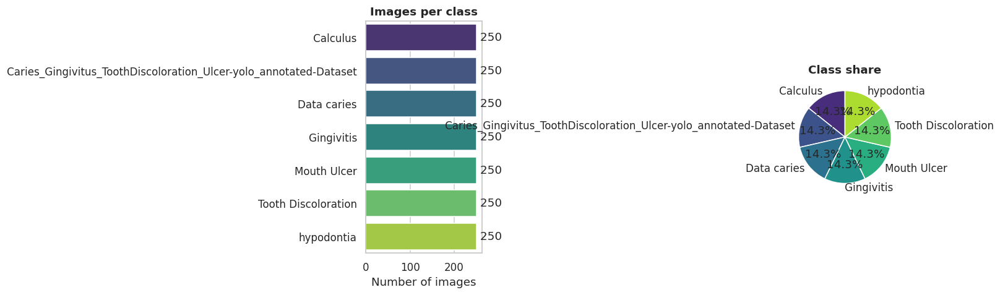

Imbalance ratio (largest / smallest class): 1.00


In [4]:
counts = df["label"].value_counts().reindex(CLASS_NAMES)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=counts.values, y=counts.index, palette="viridis", ax=axes[0])
for i, v in enumerate(counts.values):
    axes[0].text(v, i, f" {v}", va="center")
axes[0].set_title("Images per class"); axes[0].set_xlabel("Number of images"); axes[0].set_ylabel("")
axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("viridis", NUM_CLASSES))
axes[1].set_title("Class share")
plt.tight_layout(); plt.show()
print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.2f}")

### 4.2 Sample images
Four random images from every class — a quick visual check that every label really contains the expected disease.

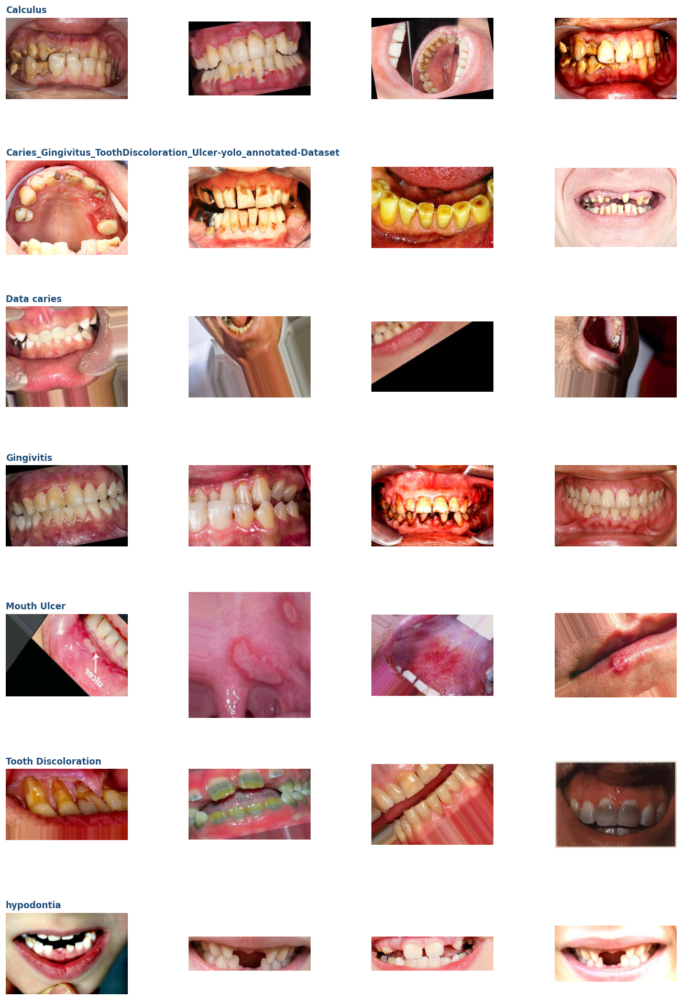

In [5]:
rng = np.random.default_rng(SEED)
n_cols = 4
fig, axes = plt.subplots(NUM_CLASSES, n_cols, figsize=(3 * n_cols, 2.6 * NUM_CLASSES))
axes = np.atleast_2d(axes)
for r, cls in enumerate(CLASS_NAMES):
    paths = df.loc[df["label"] == cls, "path"].values
    picks = rng.choice(paths, size=min(n_cols, len(paths)), replace=False)
    for c in range(n_cols):
        ax = axes[r, c]; ax.axis("off")
        if c < len(picks):
            ax.imshow(Image.open(picks[c]).convert("RGB"))
            if c == 0:
                ax.set_title(cls, loc="left", fontsize=11, color="#1f4e79")
plt.tight_layout(); plt.show()

### 4.3 Image properties
Image sizes differ; everything is resized to `IMG_SIZE` in the input pipeline.

Width  : min=123  median=325  max=612
Height : min=33  median=207  max=612


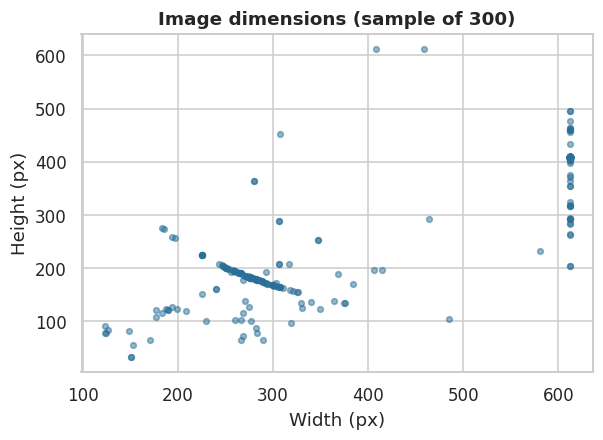

In [6]:
sample_paths = df["path"].sample(min(300, len(df)), random_state=SEED)
sizes = np.array([Image.open(p).size for p in sample_paths])
print(f"Width  : min={sizes[:,0].min()}  median={int(np.median(sizes[:,0]))}  max={sizes[:,0].max()}")
print(f"Height : min={sizes[:,1].min()}  median={int(np.median(sizes[:,1]))}  max={sizes[:,1].max()}")
plt.figure(figsize=(6, 4))
plt.scatter(sizes[:, 0], sizes[:, 1], alpha=0.5, s=14, color="#2a6f97")
plt.title("Image dimensions (sample of 300)"); plt.xlabel("Width (px)"); plt.ylabel("Height (px)")
plt.show()

## 5. Train / Validation / Test Split and Class Weights
Existing splits are kept; any missing split is carved out of the training data with **stratified** sampling. The test set is never used for training, tuning or checkpoint selection. Class weights compensate for imbalance.

In [7]:
def build_splits(frame):
    frame = frame.copy()
    frame["split"] = frame["split"].fillna("train")
    for name, frac in (("test", TEST_FRACTION), ("val", VAL_FRACTION)):
        if name not in set(frame["split"]):
            part = frame[frame["split"] == "train"]
            _, carve = train_test_split(part, test_size=frac, stratify=part["label_id"], random_state=SEED)
            frame.loc[carve.index, "split"] = name
    return frame

df = build_splits(df)
train_df = df[df["split"] == "train"].sample(frac=1, random_state=SEED).reset_index(drop=True)   # shuffled rows
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

split_table = pd.crosstab(df["label"], df["split"])[["train", "val", "test"]]
split_table.loc["TOTAL"] = split_table.sum()
display(split_table)

w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label_id"].values)
CLASS_WEIGHTS = {i: float(x) for i, x in enumerate(w)} if USE_CLASS_WEIGHTS else None
print("Class weights:", {CLASS_NAMES[i]: round(x, 2) for i, x in (CLASS_WEIGHTS or {}).items()})

split,train,val,test
label,,,
Calculus,213,0,37
Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset,206,8,36
Data caries,213,0,37
Gingivitis,212,0,38
Mouth Ulcer,212,0,38
Tooth Discoloration,212,0,38
hypodontia,212,0,38
TOTAL,1480,8,262


Class weights: {'Calculus': 0.99, 'Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset': 1.03, 'Data caries': 0.99, 'Gingivitis': 1.0, 'Mouth Ulcer': 1.0, 'Tooth Discoloration': 1.0, 'hypodontia': 1.0}


## 6. Input Pipeline and Data Augmentation
### 6.1 `tf.data` pipeline
Images are decoded once, resized, stored compactly as `uint8` in RAM (`cache`) and converted to float per batch — this makes every epoch after the first much faster. Pixel values stay in 0–255; **each model contains its own preprocessing**, so the saved model works directly on raw images.

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image_u8(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(tf.round(tf.clip_by_value(img, 0.0, 255.0)), tf.uint8), label

def to_float(x, y):
    return tf.cast(x, tf.float32), y

def make_dataset(frame, training):
    ds = tf.data.Dataset.from_tensor_slices((frame["path"].values, frame["label_id"].values.astype("int32")))
    ds = ds.map(load_image_u8, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).map(to_float, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

def build_datasets():
    global train_ds, val_ds, test_ds
    train_ds = make_dataset(train_df, training=True)
    val_ds = make_dataset(val_df, training=False)
    test_ds = make_dataset(test_df, training=False)      # not shuffled: order matches test_df
    print(f"Batch size {BATCH_SIZE} -> batches: train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}")

build_datasets()

I0000 00:00:1793136879.445292      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


Batch size 32 -> batches: train 47 | val 1 | test 9


### 6.2 Data augmentation
Random flip, rotation, zoom, translation, contrast and brightness are applied **inside the model** and are active **only during training**. They add data diversity, reduce overfitting and make the model robust to camera angle and lighting.

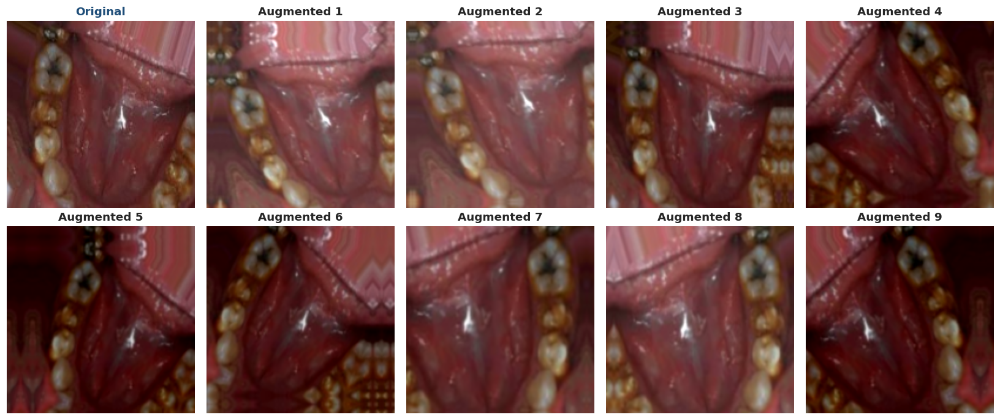

In [9]:
def build_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.15),
        layers.RandomTranslation(0.08, 0.08),
        layers.RandomContrast(0.15),
        layers.RandomBrightness(0.15, value_range=(0, 255)),
    ], name="augmentation")

aug_preview = build_augmentation()
sample_img = tf.cast(load_image_u8(train_df["path"].iloc[0], 0)[0], tf.float32)
fig, axes = plt.subplots(2, 5, figsize=(15, 6.4)); axes = axes.ravel()
axes[0].imshow(sample_img.numpy().astype("uint8")); axes[0].set_title("Original", color="#1f4e79")
for i in range(1, 10):
    out = aug_preview(tf.expand_dims(sample_img, 0), training=True)[0].numpy()
    axes[i].imshow(np.clip(out, 0, 255).astype("uint8")); axes[i].set_title(f"Augmented {i}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Reusable Experiment Toolkit
All four models share the same functions, so the comparison is fair and no code is duplicated.
### 7.1 Model builders
* **Custom CNN:** 4 blocks of (2 × Conv-BN-ReLU + MaxPool + Dropout), Global Average Pooling, regularised dense head.
* **Pretrained models:** ImageNet backbone (frozen in stage 1) + Global Average Pooling + Dropout + Dense head, each with the exact preprocessing it was trained with.
* Tunable hyperparameters: dense units, dropout, learning rate (and base filters for the custom CNN).

In [10]:
WEIGHTS = {}                                    # filled by the weight check in Section 7.2

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"],
                  jit_compile=False)                          # Keras 3 enables XLA by default on GPU -> OOM; keep it off
    return model

def build_custom_cnn(hp):
    base = hp.Choice("base_filters", [32, 48, 64])
    dense = hp.Choice("dense_units", [128, 256, 512])
    dropout = hp.Float("dropout", 0.3, 0.6, step=0.1)
    lr = hp.Float("lr", 1e-4, 3e-3, sampling="log")
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = build_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    for i, mult in enumerate([1, 2, 4, 4]):
        for j in range(2):
            stride = 2 if (i == 0 and j == 0) else 1            # strided first conv keeps early-layer memory low
            x = layers.Conv2D(base * mult, 3, strides=stride, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.10 + 0.05 * i)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return compile_model(keras.Model(inputs, outputs, name="custom_cnn"), lr)

def _torch_normalization():
    mean = np.array([0.485, 0.456, 0.406]) * 255.0
    std = np.array([0.229, 0.224, 0.225]) * 255.0
    return layers.Normalization(mean=mean.tolist(), variance=(std ** 2).tolist())

# name -> (constructor, preprocessing-layer factory or None)
BACKBONES = {
    "EfficientNetB0": (keras.applications.EfficientNetB0, None),                                    # preprocessing built in
    "ResNet50V2": (keras.applications.ResNet50V2, lambda: layers.Rescaling(1 / 127.5, offset=-1)),   # scale to [-1, 1]
    "DenseNet121": (keras.applications.DenseNet121, _torch_normalization),                           # ImageNet mean / std
}

def build_pretrained(name, hp):
    dense = hp.Choice("dense_units", [128, 256, 512])
    dropout = hp.Float("dropout", 0.2, 0.5, step=0.1)
    lr = hp.Float("lr", 1e-4, 3e-3, sampling="log")
    ctor, prep = BACKBONES[name]
    weights = WEIGHTS.get(name)
    pretrained = weights is not None

    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = build_augmentation()(inputs)
    if prep is not None:
        x = prep()(x)
    backbone = ctor(include_top=False, weights=weights, input_shape=(*IMG_SIZE, 3), name="backbone")
    backbone.trainable = not pretrained                      # frozen in stage 1 only when ImageNet weights are loaded
    x = backbone(x, training=False) if pretrained else backbone(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense, activation="relu")(x)
    x = layers.Dropout(dropout / 2)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return compile_model(keras.Model(inputs, outputs, name=name.lower()), lr)

def build_model(name, hp):
    return build_custom_cnn(hp) if name == "Custom CNN" else build_pretrained(name, hp)

### 7.2 ImageNet weights check
For each pretrained model the notebook tries, in order: **(1)** the official ImageNet download, **(2)** a local weights file found in any attached Kaggle dataset (file name containing the model name and `notop`), **(3)** random initialisation as a last resort (the backbone is then trained fully from scratch so nothing crashes — accuracy will be lower). The result is shown in the comparison table.

In [11]:
def resolve_weights(name):
    ctor = BACKBONES[name][0]
    try:
        ctor(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
        return "imagenet"
    except Exception as e:
        print(f"   ImageNet download unavailable for {name} ({type(e).__name__}); searching attached datasets...")
    key = name.lower()
    for p in Path("/kaggle/input").rglob("*"):
        low = p.name.lower()
        if p.suffix in {".h5", ".keras"} and key in low and ("notop" in low or "no_top" in low):
            try:
                ctor(include_top=False, weights=str(p), input_shape=(*IMG_SIZE, 3))
                return str(p)
            except Exception:
                continue
    return None

for _name in BACKBONES:
    WEIGHTS[_name] = resolve_weights(_name)
    status = {"imagenet": "ImageNet weights (download)", None: "NOT FOUND -> will train from scratch (lower accuracy)"}.get(WEIGHTS[_name], f"local file {WEIGHTS[_name]}")
    print(f"[{'OK' if WEIGHTS[_name] else 'WARN'}] {_name}: {status}")
    keras.backend.clear_session(); gc.collect()
if not all(WEIGHTS.values()):
    print("\nTip: set Internet -> On in the notebook settings (or attach a dataset containing '<model>_notop.h5' files) and run again for full accuracy.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[OK] EfficientNetB0: ImageNet weights (download)
94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
[OK] ResNet50V2: ImageNet weights (download)
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[OK] DenseNet121: ImageNet weights (download)


### 7.3 Callbacks — learning-rate scheduling, best-weights checkpoint, early stopping
| Callback | Role |
|----------|------|
| `ModelCheckpoint` | Saves the weights of the epoch with the **best validation accuracy** |
| `EarlyStopping` | Stops when validation accuracy stops improving and restores the best weights |
| `ReduceLROnPlateau` | Multiplies the learning rate by 0.3 when validation loss plateaus |

After every stage the best checkpoint is reloaded explicitly, so the evaluated model is always the best one, not the last one.

In [12]:
def make_callbacks(tag, stage):
    ckpt_path = CKPT_DIR / f"{tag}_{stage}.weights.h5"
    callbacks = [
        keras.callbacks.ModelCheckpoint(str(ckpt_path), monitor="val_accuracy", mode="max",
                                        save_best_only=True, save_weights_only=True, verbose=0),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=EARLY_STOP_PATIENCE,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=LR_FACTOR, patience=LR_PATIENCE,
                                          min_lr=MIN_LR, verbose=1),
    ]
    return callbacks, ckpt_path

def train_stage(model, tag, stage, epochs):
    callbacks, ckpt_path = make_callbacks(tag, stage)
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks,
                        class_weight=CLASS_WEIGHTS, verbose=2)
    model.load_weights(str(ckpt_path))                       # best weights of this stage
    return history.history, ckpt_path

### 7.4 Automatic hyperparameter tuning (Keras Tuner)
A random search tries several hyperparameter combinations for a few epochs each and keeps the best by validation accuracy. If the search fails for any reason the notebook falls back to default hyperparameters instead of stopping.

In [13]:
def tune_model(name):
    try:
        tuner = kt.RandomSearch(
            hypermodel=lambda hp: build_model(name, hp),
            objective="val_accuracy", max_trials=TUNER_TRIALS, executions_per_trial=1,
            max_consecutive_failed_trials=TUNER_TRIALS,
            directory=str(TUNER_DIR), project_name=name.replace(" ", "_"), overwrite=True, seed=SEED)
        tuner.search(train_ds, validation_data=val_ds, epochs=TUNER_EPOCHS, class_weight=CLASS_WEIGHTS,
                     callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=2)], verbose=2)
        best_hp = tuner.get_best_hyperparameters(1)[0]
    except Exception as e:
        print(f"Tuner problem ({type(e).__name__}) -> using default hyperparameters for {name}.")
        best_hp = kt.HyperParameters()
    keras.backend.clear_session(); gc.collect()
    return best_hp

### 7.5 Two-stage training, fine-tuning and automatic recovery
1. **Stage 1** – pretrained models train only the new head (backbone frozen); the custom CNN trains from scratch.
2. **Stage 2 (fine-tuning)** – the top backbone layers are unfrozen (BatchNorm stays frozen) and training continues with a very small learning rate; the custom CNN continues with a reduced learning rate.

If stage 2 does not beat stage 1 on validation data, the stage-1 weights are restored. After evaluation each model is saved to disk and released from GPU memory; `safe_run` retries with a smaller batch size if an experiment fails.

In [14]:
def unfreeze_top_layers(model, n_layers, pretrained):
    backbone = model.get_layer("backbone")
    backbone.trainable = True
    if pretrained:
        for layer in backbone.layers[:-n_layers]:
            layer.trainable = False
        for layer in backbone.layers:
            if isinstance(layer, layers.BatchNormalization):
                layer.trainable = False

def run_experiment(name):
    tag = name.replace(" ", "_")
    print("=" * 90, f"\n  EXPERIMENT: {name}   (batch size {BATCH_SIZE})\n", "=" * 90, sep="")
    best_hp = tune_model(name)
    model = build_model(name, best_hp)
    pretrained = name == "Custom CNN" or WEIGHTS.get(name) is not None

    start = time.time()
    print(f"\n--- Stage 1: {'training from scratch' if name == 'Custom CNN' or not pretrained else 'training the head (frozen backbone)'} ---")
    h1, ckpt1 = train_stage(model, tag, "stage1", EPOCHS_CUSTOM if name == "Custom CNN" else EPOCHS_HEAD)

    print("\n--- Stage 2: fine-tuning ---")
    if name == "Custom CNN":
        compile_model(model, FT_LR_CUSTOM)
    else:
        unfreeze_top_layers(model, FT_LAYERS[name], pretrained)
        compile_model(model, FT_LR if pretrained else FT_LR_SCRATCH)
    h2, ckpt2 = train_stage(model, tag, "stage2", EPOCHS_FT)

    final_stage = "stage 2 (fine-tuned)"
    if max(h2["val_accuracy"]) < max(h1["val_accuracy"]):
        model.load_weights(str(ckpt1)); final_stage = "stage 1 (fine-tuning did not improve validation accuracy)"
    elapsed = time.time() - start

    weights_info = "-" if name == "Custom CNN" else ("ImageNet" if WEIGHTS.get(name) == "imagenet" else ("local file" if WEIGHTS.get(name) else "none (random init)"))
    history = {k: h1.get(k, []) + h2.get(k, []) for k in set(h1) | set(h2)}
    res = dict(name=name, model=model, history=history, stage1_epochs=len(h1["loss"]), best_hp=dict(best_hp.values),
               train_time=elapsed, params=model.count_params(), final_stage=final_stage, weights_info=weights_info,
               stage1_best_val=max(h1["val_accuracy"]), stage2_best_val=max(h2["val_accuracy"]), batch_size=BATCH_SIZE)
    res = evaluate_model(res)

    res["model_path"] = str(CKPT_DIR / f"{tag}_final.keras")
    res["model"].save(res["model_path"])
    res.pop("model")                                          # release GPU memory; the model lives on disk
    del model
    keras.backend.clear_session(); gc.collect()
    return res

def safe_run(name):
    global BATCH_SIZE
    for attempt in (1, 2, 3):
        try:
            RESULTS[name] = run_experiment(name)
            return RESULTS[name]
        except Exception as e:
            print(f"\n[{name}] attempt {attempt} failed: {type(e).__name__}: {str(e)[:200]}")
            keras.backend.clear_session(); gc.collect()
            if attempt < 3:
                BATCH_SIZE = max(8, BATCH_SIZE // 2)
                print(f"Retrying with batch size {BATCH_SIZE} ...")
                build_datasets()
    print(f"[{name}] skipped after repeated failures; the remaining models will still run.")
    return None

### 7.6 Evaluation on the held-out test set
Accuracy, macro / weighted precision, recall and F1, multi-class ROC-AUC (one-vs-rest), confusion matrix and the full per-class report.

In [15]:
def evaluate_model(res):
    probs = res["model"].predict(test_ds, verbose=0)
    y_true = test_df["label_id"].values
    y_pred = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    _, _, wf1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    try:
        auc = roc_auc_score(y_true, probs, multi_class="ovr", average="macro")
    except Exception:
        auc = float("nan")
    res.update(probs=probs, y_true=y_true, y_pred=y_pred, accuracy=accuracy_score(y_true, y_pred),
               precision=p, recall=r, f1=f1, weighted_f1=wf1, auc=auc,
               cm=confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES)),
               report=classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASS_NAMES, output_dict=True, zero_division=0),
               report_text=classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASS_NAMES, digits=4, zero_division=0))
    print(f"\n>>> {res['name']}: Test accuracy = {res['accuracy']:.4f} | Macro F1 = {res['f1']:.4f} | Training time = {res['train_time']/60:.1f} min")
    return res

### 7.7 Visualisation helpers
Training curves (accuracy, loss, learning rate), confusion matrices (counts and normalised), per-class precision / recall / F1 and a grid of test predictions.

In [16]:
def plot_history(res):
    h, split = res["history"], res["stage1_epochs"]
    best = int(np.argmax(h["val_accuracy"]))
    lr_key = "learning_rate" if "learning_rate" in h else ("lr" if "lr" in h else None)
    fig, axes = plt.subplots(1, 3 if lr_key else 2, figsize=(17 if lr_key else 12, 4.2))
    for ax, key, title in zip(axes[:2], ["accuracy", "loss"], ["Accuracy", "Loss"]):
        ax.plot(h[key], label="train", lw=2); ax.plot(h["val_" + key], label="validation", lw=2)
        ax.axvline(split - 0.5, color="gray", ls="--", label="fine-tuning starts")
        if key == "accuracy":
            ax.scatter(best, h["val_accuracy"][best], color="red", zorder=5, label=f"best val (epoch {best+1})")
        ax.set_title(f"{res['name']} - {title}"); ax.set_xlabel("Epoch"); ax.legend()
    if lr_key:
        axes[2].plot(h[lr_key], color="#d62728", lw=2); axes[2].set_yscale("log"); axes[2].axvline(split - 0.5, color="gray", ls="--")
        axes[2].set_title(f"{res['name']} - Learning rate"); axes[2].set_xlabel("Epoch")
    plt.tight_layout(); plt.show()

def plot_confusion(res):
    cm = res["cm"]; cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    size = max(6, NUM_CLASSES * 0.9)
    fig, axes = plt.subplots(1, 2, figsize=(2 * size + 2, size))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0], cbar=False)
    axes[0].set_title(f"{res['name']} - Confusion matrix (counts)")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1], vmin=0, vmax=1)
    axes[1].set_title(f"{res['name']} - Confusion matrix (row-normalised)")
    for ax in axes:
        ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

def plot_class_metrics(res):
    print(res["report_text"])
    rep = pd.DataFrame(res["report"]).T.loc[CLASS_NAMES, ["precision", "recall", "f1-score"]]
    ax = rep.plot(kind="bar", figsize=(max(9, NUM_CLASSES * 1.4), 4.2), width=0.8, colormap="viridis")
    ax.set_ylim(0, 1.05); ax.set_title(f"{res['name']} - Per-class precision / recall / F1"); ax.set_xlabel("")
    plt.xticks(rotation=30, ha="right"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

def plot_predictions(res, n=12):
    idx = np.random.default_rng(SEED).choice(len(test_df), size=min(n, len(test_df)), replace=False)
    cols = 4; rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 3.4 * rows))
    flat = np.atleast_1d(axes).ravel()
    for ax, i in zip(flat, idx):
        t, p = res["y_true"][i], res["y_pred"][i]
        ax.imshow(Image.open(test_df["path"].iloc[i]).convert("RGB").resize(IMG_SIZE)); ax.axis("off")
        ax.set_title(f"True: {CLASS_NAMES[t]}\nPred: {CLASS_NAMES[p]} ({res['probs'][i, p]*100:.0f}%)",
                     color="green" if t == p else "red", fontsize=9)
    for ax in flat[len(idx):]: ax.axis("off")
    plt.suptitle(f"{res['name']} - Test predictions (green = correct, red = wrong)", fontweight="bold")
    plt.tight_layout(); plt.show()

def show_results(name):
    res = RESULTS.get(name)
    if res is None:
        print(f"{name}: no results (this experiment was skipped)."); return
    plot_history(res); plot_confusion(res); plot_class_metrics(res); plot_predictions(res)

### 7.8 Automatic discussion of each model's results
Reads the measured numbers and writes the analysis: generalisation (train vs. validation gap), effect of fine-tuning, strongest / weakest classes and the most confused class pair.

In [17]:
def discuss(name):
    res = RESULTS.get(name)
    if res is None:
        print(f"{name}: no results to discuss."); return
    h = res["history"]; va = np.array(h["val_accuracy"]); ta = np.array(h["accuracy"]); b = int(va.argmax())
    gap = ta[b] - va[b]
    if gap > 0.10:    fit = "strong overfitting (training accuracy far above validation accuracy)"
    elif gap > 0.04:  fit = "mild overfitting"
    elif gap < -0.02: fit = "no overfitting - training accuracy is lower because augmentation and dropout are active during training"
    else:             fit = "good generalisation (train and validation accuracy are close)"
    f1s = {c: res["report"][c]["f1-score"] for c in CLASS_NAMES}
    best_c, worst_c = max(f1s, key=f1s.get), min(f1s, key=f1s.get)
    off = res["cm"].copy(); np.fill_diagonal(off, 0)
    i, j = np.unravel_index(off.argmax(), off.shape)
    delta = res["stage2_best_val"] - res["stage1_best_val"]
    lines = [
        f"{name} reached {res['accuracy']*100:.2f}% test accuracy (macro F1 = {res['f1']:.3f}, weighted F1 = {res['weighted_f1']:.3f}, macro ROC-AUC = {res['auc']:.3f}). Weights: {res['weights_info']}.",
        f"Generalisation: best validation epoch = {b+1}; the model shows {fit} (train-val gap = {gap*100:+.1f} points).",
        f"Fine-tuning: best validation accuracy went from {res['stage1_best_val']*100:.2f}% (stage 1) to {res['stage2_best_val']*100:.2f}% (stage 2), a change of {delta*100:+.2f} points. Final weights come from {res['final_stage']}.",
        f"Classes: easiest = '{best_c}' (F1 = {f1s[best_c]:.3f}); hardest = '{worst_c}' (F1 = {f1s[worst_c]:.3f}).",
        (f"Most frequent confusion: '{CLASS_NAMES[i]}' predicted as '{CLASS_NAMES[j]}' ({off[i, j]} cases) - these classes look visually similar to the model."
         if off.max() > 0 else "No misclassified test images."),
        f"Cost: {res['params']/1e6:.2f}M parameters, {res['train_time']/60:.1f} minutes of training. Selected hyperparameters: {res['best_hp']}.",
    ]
    print("\n".join(textwrap.fill(l, 130, subsequent_indent="    ", initial_indent="• ") for l in lines))

## 8. Model 1 — Custom CNN
A convolutional network designed and trained from scratch. It is the **baseline** that shows how far a purpose-built architecture goes without transfer learning.
### 8.1 Architecture

In [18]:
build_custom_cnn(kt.HyperParameters()).summary()
keras.backend.clear_session(); gc.collect();

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 80, 80, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 80, 80, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 40, 40, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 40, 40, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 20, 20, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 20, 20, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 601,703 (2.30 MB)

 Trainable params: 600,295 (2.29 MB)

 Non-trainable params: 1,408 (5.50 KB)

### 8.2 Tuning, training and fine-tuning
Random search, training with all callbacks, fine-tuning at a lower learning rate, then evaluation on the test set.

In [19]:
safe_run("Custom CNN");

Trial 2 Complete [00h 00m 13s]
val_accuracy: 0.0

Best val_accuracy So Far: 0.0
Total elapsed time: 00h 00m 40s

--- Stage 1: training from scratch ---
Epoch 1/10
47/47 - 9s - 196ms/step - accuracy: 0.2419 - loss: 1.9758 - val_accuracy: 0.0000e+00 - val_loss: 2.1941 - learning_rate: 2.5211e-04
Epoch 2/10

Epoch 2: ReduceLROnPlateau reducing learning rate to 7.563350081909447e-05.
47/47 - 3s - 67ms/step - accuracy: 0.3311 - loss: 1.6951 - val_accuracy: 0.0000e+00 - val_loss: 2.6986 - learning_rate: 2.5211e-04
Epoch 3/10

Epoch 3: ReduceLROnPlateau reducing learning rate to 2.2690049809170885e-05.
47/47 - 3s - 67ms/step - accuracy: 0.3932 - loss: 1.5452 - val_accuracy: 0.0000e+00 - val_loss: 3.1923 - learning_rate: 7.5633e-05
Epoch 4/10

Epoch 4: ReduceLROnPlateau reducing learning rate to 6.8070150518906304e-06.
47/47 - 3s - 67ms/step - accuracy: 0.4155 - loss: 1.4757 - val_accuracy: 0.0000e+00 - val_loss: 3.3468 - learning_rate: 2.2690e-05
Epoch 4: early stopping
Restoring model weight

### 8.3 Results and graphs
Training curves, confusion matrices, per-class report and sample predictions.

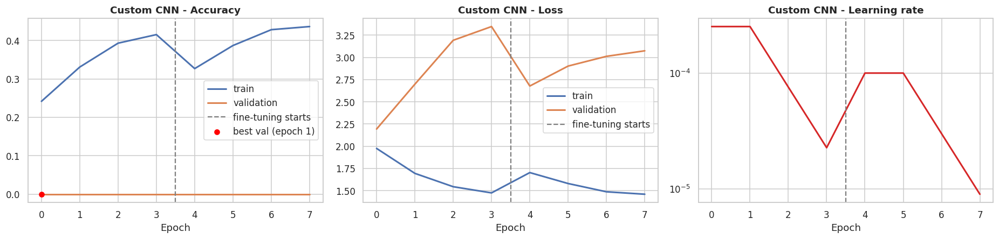

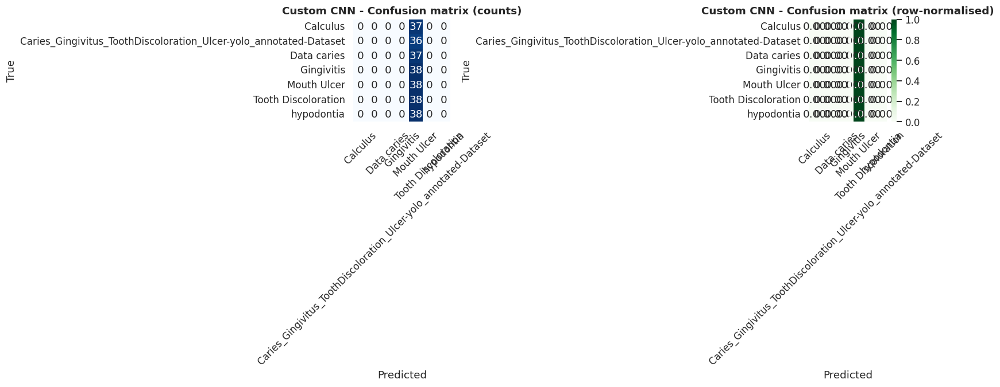

                                                                   precision    recall  f1-score   support

                                                         Calculus     0.0000    0.0000    0.0000        37
Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset     0.0000    0.0000    0.0000        36
                                                      Data caries     0.0000    0.0000    0.0000        37
                                                       Gingivitis     0.0000    0.0000    0.0000        38
                                                      Mouth Ulcer     0.1450    1.0000    0.2533        38
                                              Tooth Discoloration     0.0000    0.0000    0.0000        38
                                                       hypodontia     0.0000    0.0000    0.0000        38

                                                         accuracy                         0.1450       262
                                   

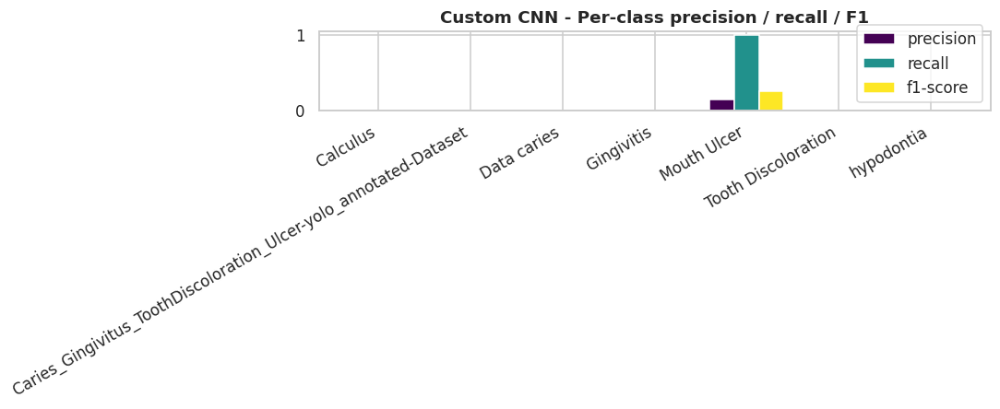

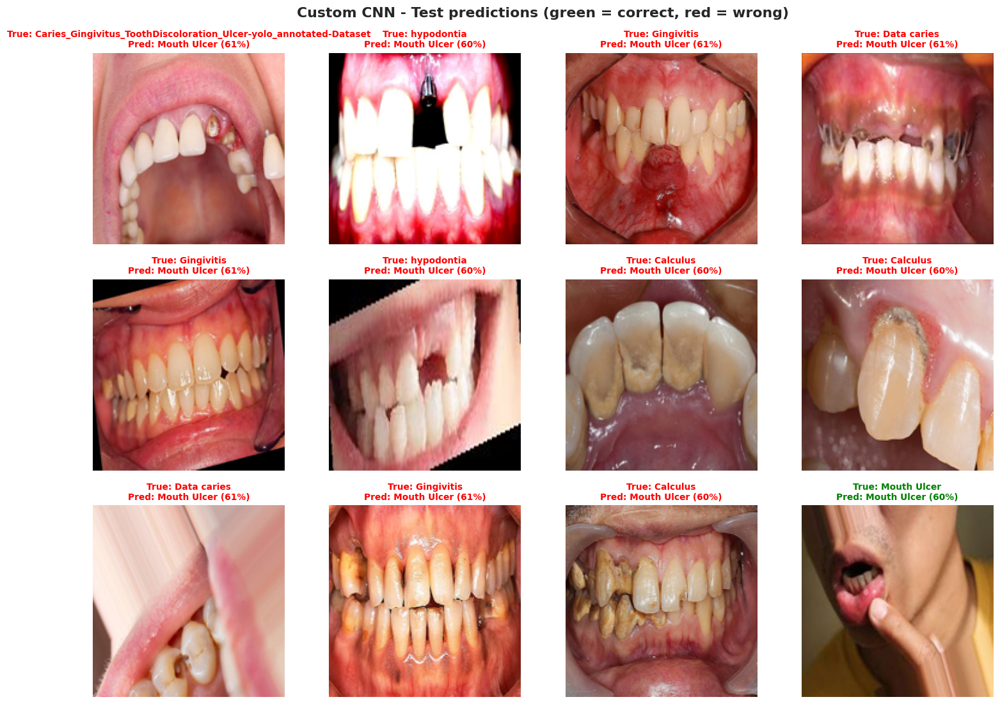

In [20]:
show_results("Custom CNN")

### 8.4 Discussion — Custom CNN

In [21]:
discuss("Custom CNN")

• Custom CNN reached 14.50% test accuracy (macro F1 = 0.036, weighted F1 = 0.037, macro ROC-AUC = 0.603). Weights: -.
• Generalisation: best validation epoch = 1; the model shows strong overfitting (training accuracy far above validation accuracy)
    (train-val gap = +24.2 points).
• Fine-tuning: best validation accuracy went from 0.00% (stage 1) to 0.00% (stage 2), a change of +0.00 points. Final weights come
    from stage 2 (fine-tuned).
• Classes: easiest = 'Mouth Ulcer' (F1 = 0.253); hardest = 'Calculus' (F1 = 0.000).
• Most frequent confusion: 'Gingivitis' predicted as 'Mouth Ulcer' (38 cases) - these classes look visually similar to the model.
• Cost: 1.34M parameters, 0.6 minutes of training. Selected hyperparameters: {'base_filters': 48, 'dense_units': 128, 'dropout':
    0.4, 'lr': 0.00025211167233273865}.


## 9. Model 2 — EfficientNetB0 (Transfer Learning + Fine-Tuning)
A compound-scaled, parameter-efficient network (≈5M parameters) with the best accuracy-per-parameter ratio — a strong deployment candidate.
### 9.1 Tuning, training and fine-tuning
Stage 1 trains the new head on the frozen backbone; stage 2 unfreezes the top backbone layers and fine-tunes them with a very small learning rate.

In [22]:
safe_run("EfficientNetB0");

  EXPERIMENT: EfficientNetB0   (batch size 32)
Tuner problem (Exception) -> using default hyperparameters for EfficientNetB0.

[EfficientNetB0] attempt 1 failed: Exception: URL fetch failure on https://storage.googleapis.com/keras-applications/backbone_notop.h5: 403 -- Forbidden
Retrying with batch size 16 ...
Batch size 16 -> batches: train 93 | val 1 | test 17
  EXPERIMENT: EfficientNetB0   (batch size 16)
Tuner problem (Exception) -> using default hyperparameters for EfficientNetB0.

[EfficientNetB0] attempt 2 failed: Exception: URL fetch failure on https://storage.googleapis.com/keras-applications/backbone_notop.h5: 403 -- Forbidden
Retrying with batch size 8 ...
Batch size 8 -> batches: train 185 | val 1 | test 33
  EXPERIMENT: EfficientNetB0   (batch size 8)
Tuner problem (Exception) -> using default hyperparameters for EfficientNetB0.

[EfficientNetB0] attempt 3 failed: Exception: URL fetch failure on https://storage.googleapis.com/keras-applications/backbone_notop.h5: 403 -- Fo

### 9.2 Results and graphs
Training curves, confusion matrices, per-class report and sample predictions for EfficientNetB0.

In [23]:
show_results("EfficientNetB0")

EfficientNetB0: no results (this experiment was skipped).


### 9.3 Discussion — EfficientNetB0

In [24]:
discuss("EfficientNetB0")

EfficientNetB0: no results to discuss.


## 10. Model 3 — ResNet50V2 (Transfer Learning + Fine-Tuning)
A deep residual network (≈24M parameters) with pre-activation residual blocks; skip connections make deep networks easy to optimise, a robust transfer-learning classic.
### 10.1 Tuning, training and fine-tuning
Stage 1 trains the new head on the frozen backbone; stage 2 unfreezes the top backbone layers and fine-tunes them with a very small learning rate.

In [25]:
safe_run("ResNet50V2");

Trial 2 Complete [00h 00m 15s]
val_accuracy: 0.125

Best val_accuracy So Far: 0.125
Total elapsed time: 00h 00m 32s

--- Stage 1: training the head (frozen backbone) ---
Epoch 1/3
185/185 - 14s - 74ms/step - accuracy: 0.3601 - loss: 1.8947 - val_accuracy: 0.2500 - val_loss: 1.7821 - learning_rate: 4.0129e-04
Epoch 2/3
185/185 - 4s - 24ms/step - accuracy: 0.5034 - loss: 1.3281 - val_accuracy: 0.2500 - val_loss: 1.5988 - learning_rate: 4.0129e-04
Epoch 3/3
185/185 - 4s - 24ms/step - accuracy: 0.5554 - loss: 1.1838 - val_accuracy: 0.1250 - val_loss: 1.5346 - learning_rate: 4.0129e-04
Restoring model weights from the end of the best epoch: 1.

--- Stage 2: fine-tuning ---
Epoch 1/4
185/185 - 20s - 110ms/step - accuracy: 0.5250 - loss: 1.2296 - val_accuracy: 0.2500 - val_loss: 1.5293 - learning_rate: 3.0000e-05
Epoch 2/4
185/185 - 8s - 46ms/step - accuracy: 0.6338 - loss: 0.9597 - val_accuracy: 0.2500 - val_loss: 1.2523 - learning_rate: 3.0000e-05
Epoch 3/4
185/185 - 9s - 51ms/step - accura

### 10.2 Results and graphs
Training curves, confusion matrices, per-class report and sample predictions for ResNet50V2.

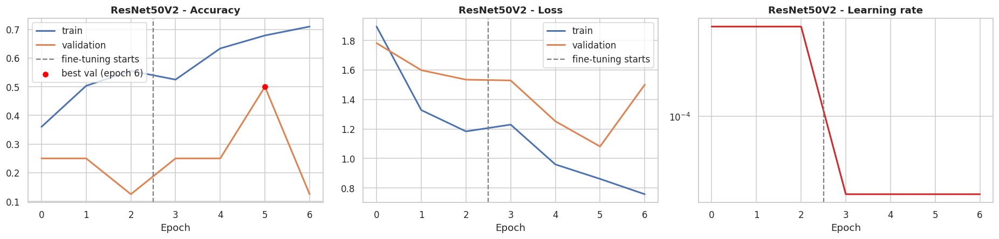

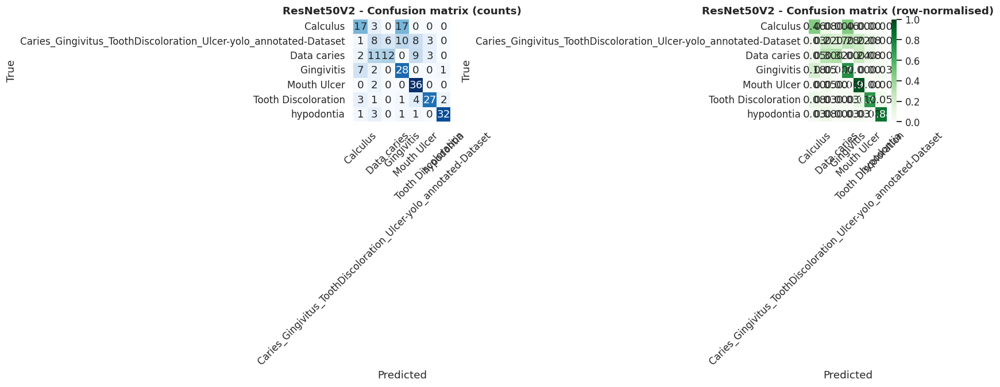

                                                                   precision    recall  f1-score   support

                                                         Calculus     0.5484    0.4595    0.5000        37
Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset     0.2667    0.2222    0.2424        36
                                                      Data caries     0.6667    0.3243    0.4364        37
                                                       Gingivitis     0.4912    0.7368    0.5895        38
                                                      Mouth Ulcer     0.6207    0.9474    0.7500        38
                                              Tooth Discoloration     0.8182    0.7105    0.7606        38
                                                       hypodontia     0.9143    0.8421    0.8767        38

                                                         accuracy                         0.6107       262
                                   

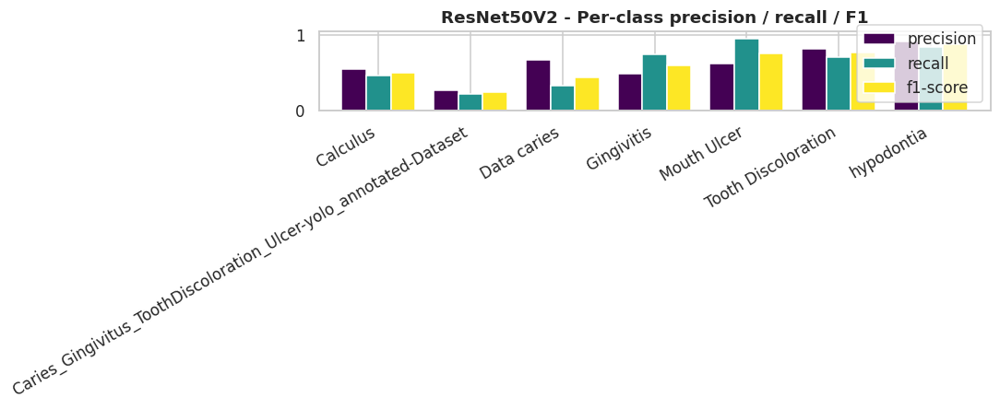

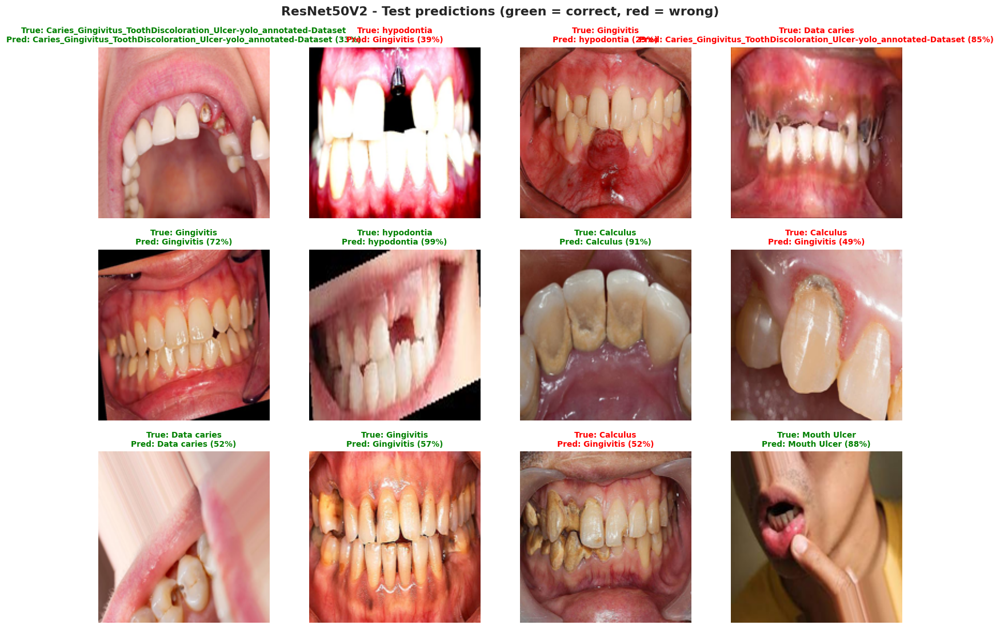

In [26]:
show_results("ResNet50V2")

### 10.3 Discussion — ResNet50V2

In [27]:
discuss("ResNet50V2")

• ResNet50V2 reached 61.07% test accuracy (macro F1 = 0.594, weighted F1 = 0.597, macro ROC-AUC = 0.908). Weights: ImageNet.
• Generalisation: best validation epoch = 6; the model shows strong overfitting (training accuracy far above validation accuracy)
    (train-val gap = +17.9 points).
• Fine-tuning: best validation accuracy went from 25.00% (stage 1) to 50.00% (stage 2), a change of +25.00 points. Final weights
    come from stage 2 (fine-tuned).
• Classes: easiest = 'hypodontia' (F1 = 0.877); hardest = 'Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset' (F1
    = 0.242).
• Most frequent confusion: 'Calculus' predicted as 'Gingivitis' (17 cases) - these classes look visually similar to the model.
• Cost: 24.09M parameters, 1.2 minutes of training. Selected hyperparameters: {'dense_units': 256, 'dropout': 0.2, 'lr':
    0.00040128879246978144}.


## 11. Model 4 — DenseNet121 (Transfer Learning + Fine-Tuning)
A densely connected network (≈7M parameters) where every layer receives the feature maps of all earlier layers; strong feature reuse works well on small medical-style datasets.
### 11.1 Tuning, training and fine-tuning
Stage 1 trains the new head on the frozen backbone; stage 2 unfreezes the top backbone layers and fine-tunes them with a very small learning rate.

In [28]:
safe_run("DenseNet121");

Trial 2 Complete [00h 00m 26s]
val_accuracy: 0.125

Best val_accuracy So Far: 0.5
Total elapsed time: 00h 00m 52s

--- Stage 1: training the head (frozen backbone) ---
Epoch 1/3
185/185 - 23s - 126ms/step - accuracy: 0.3649 - loss: 1.8071 - val_accuracy: 0.2500 - val_loss: 1.8337 - learning_rate: 4.0129e-04
Epoch 2/3
185/185 - 7s - 37ms/step - accuracy: 0.4939 - loss: 1.3360 - val_accuracy: 0.3750 - val_loss: 1.2056 - learning_rate: 4.0129e-04
Epoch 3/3

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.00012038663844577968.
185/185 - 6s - 30ms/step - accuracy: 0.5378 - loss: 1.2018 - val_accuracy: 0.1250 - val_loss: 1.4539 - learning_rate: 4.0129e-04
Restoring model weights from the end of the best epoch: 2.

--- Stage 2: fine-tuning ---
Epoch 1/4
185/185 - 29s - 155ms/step - accuracy: 0.5554 - loss: 1.1448 - val_accuracy: 0.3750 - val_loss: 1.2220 - learning_rate: 3.0000e-05
Epoch 2/4

Epoch 2: ReduceLROnPlateau reducing learning rate to 8.999999772640877e-06.
185/185 - 7s - 37m

### 11.2 Results and graphs
Training curves, confusion matrices, per-class report and sample predictions for DenseNet121.

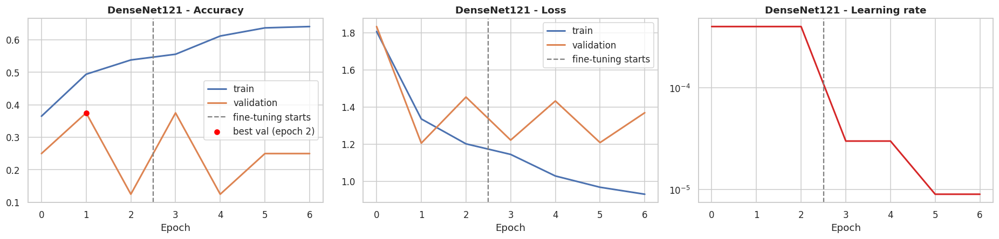

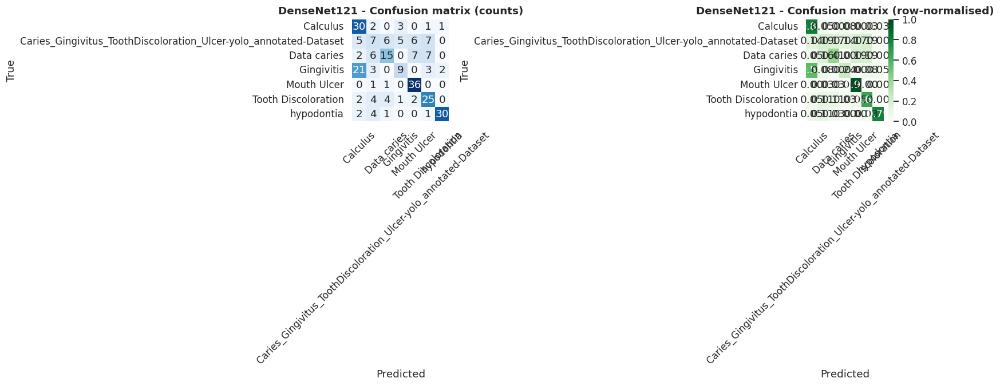

                                                                   precision    recall  f1-score   support

                                                         Calculus     0.4839    0.8108    0.6061        37
Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset     0.2593    0.1944    0.2222        36
                                                      Data caries     0.5556    0.4054    0.4688        37
                                                       Gingivitis     0.5000    0.2368    0.3214        38
                                                      Mouth Ulcer     0.7059    0.9474    0.8090        38
                                              Tooth Discoloration     0.5682    0.6579    0.6098        38
                                                       hypodontia     0.9091    0.7895    0.8451        38

                                                         accuracy                         0.5802       262
                                   

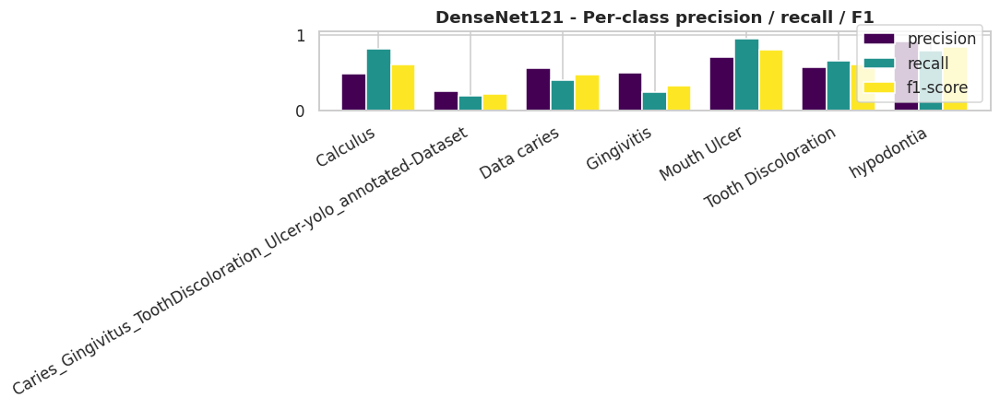

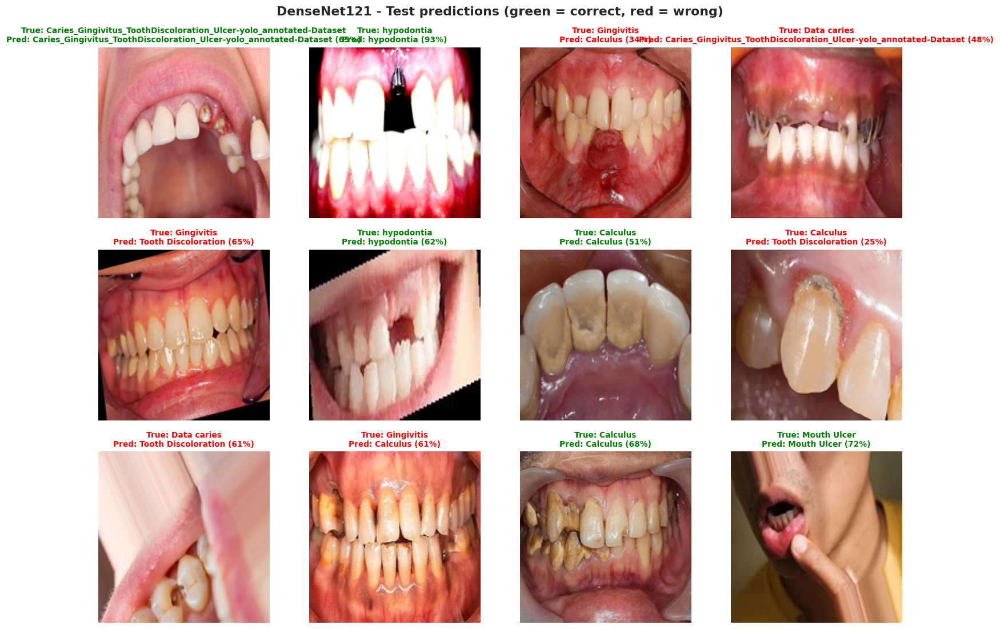

In [29]:
show_results("DenseNet121")

### 11.3 Discussion — DenseNet121

In [30]:
discuss("DenseNet121")

• DenseNet121 reached 58.02% test accuracy (macro F1 = 0.555, weighted F1 = 0.557, macro ROC-AUC = 0.905). Weights: ImageNet.
• Generalisation: best validation epoch = 2; the model shows strong overfitting (training accuracy far above validation accuracy)
    (train-val gap = +11.9 points).
• Fine-tuning: best validation accuracy went from 37.50% (stage 1) to 37.50% (stage 2), a change of +0.00 points. Final weights
    come from stage 2 (fine-tuned).
• Classes: easiest = 'hypodontia' (F1 = 0.845); hardest = 'Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset' (F1
    = 0.222).
• Most frequent confusion: 'Gingivitis' predicted as 'Calculus' (21 cases) - these classes look visually similar to the model.
• Cost: 7.30M parameters, 1.5 minutes of training. Selected hyperparameters: {'dense_units': 256, 'dropout': 0.2, 'lr':
    0.00040128879246978144}.


## 12. Comparative Analysis of the Four Models
### 12.1 Summary table
All models are evaluated on the **same untouched test set**, ranked by test accuracy with macro F1 as tie-breaker (important with imbalanced classes).

In [31]:
AVAILABLE = [n for n in MODEL_NAMES if n in RESULTS]
assert AVAILABLE, "No model finished training - see the error messages above."
rows = []
for n in AVAILABLE:
    r = RESULTS[n]; h = r["history"]; b = int(np.argmax(h["val_accuracy"]))
    rows.append({"Model": n, "ImageNet Weights": r["weights_info"], "Test Accuracy": r["accuracy"], "Macro Precision": r["precision"],
                 "Macro Recall": r["recall"], "Macro F1": r["f1"], "Weighted F1": r["weighted_f1"], "ROC-AUC": r["auc"],
                 "Best Val Acc": max(h["val_accuracy"]), "Train-Val Gap": h["accuracy"][b] - h["val_accuracy"][b],
                 "Params (M)": r["params"] / 1e6, "Train Time (min)": r["train_time"] / 60, "Epochs run": len(h["loss"])})
summary_df = pd.DataFrame(rows).sort_values(["Test Accuracy", "Macro F1"], ascending=False).reset_index(drop=True)
summary_df.to_csv(WORK_DIR / "model_comparison.csv", index=False)
fmt = {c: "{:.4f}" for c in ["Test Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1", "ROC-AUC", "Best Val Acc", "Train-Val Gap"]}
fmt.update({"Params (M)": "{:.2f}", "Train Time (min)": "{:.1f}"})
display(summary_df.style.format(fmt).background_gradient(subset=["Test Accuracy", "Macro F1"], cmap="Greens"))

,Model,ImageNet Weights,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,ROC-AUC,Best Val Acc,Train-Val Gap,Params (M),Train Time (min),Epochs run
0,ResNet50V2,ImageNet,0.6107,0.6180,0.6061,0.5936,0.5973,0.9082,0.5000,0.1791,24.09,1.2,7
1,DenseNet121,ImageNet,0.5802,0.5688,0.5775,0.5546,0.5573,0.9047,0.3750,0.1189,7.30,1.5,7
2,Custom CNN,-,0.1450,0.0207,0.1429,0.0362,0.0367,0.6035,0.0000,0.2419,1.34,0.6,8


### 12.2 Visual comparison
Test accuracy, macro F1, model size and training time side by side.

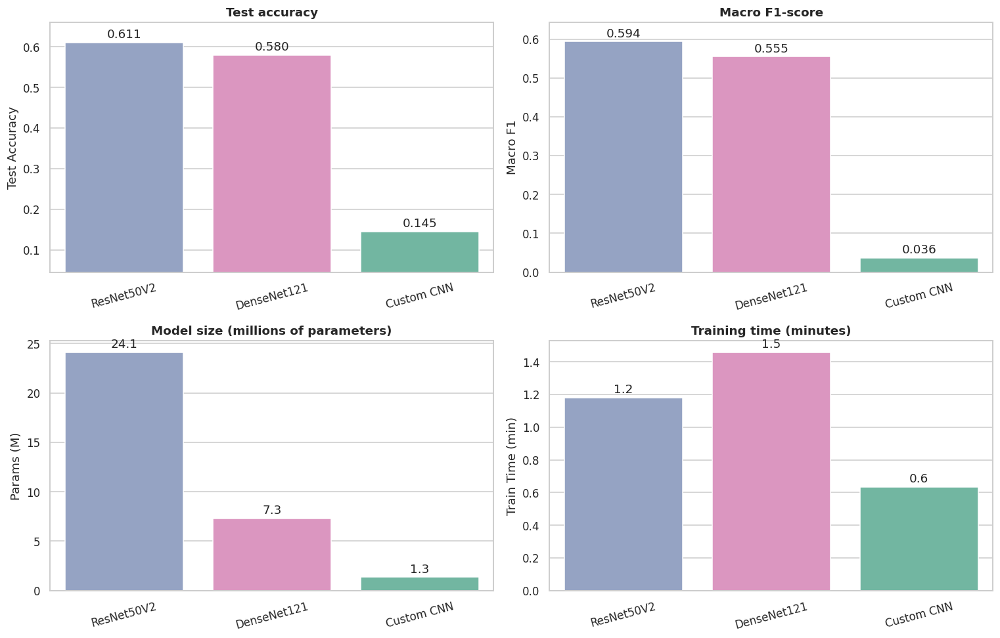

In [32]:
palette = dict(zip(MODEL_NAMES, sns.color_palette("Set2", len(MODEL_NAMES))))
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col, title in zip(axes.ravel(), ["Test Accuracy", "Macro F1", "Params (M)", "Train Time (min)"],
                          ["Test accuracy", "Macro F1-score", "Model size (millions of parameters)", "Training time (minutes)"]):
    sns.barplot(data=summary_df, x="Model", y=col, palette=palette, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f" if col in ("Test Accuracy", "Macro F1") else "%.1f", padding=2)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
    if col in ("Test Accuracy", "Macro F1"):
        ax.set_ylim(max(0, summary_df[col].min() - 0.1), min(1.02, summary_df[col].max() + 0.05))
plt.tight_layout(); plt.show()

### 12.3 Learning curves of all models
Validation accuracy and loss of all models on the same axes (fine-tuning included).

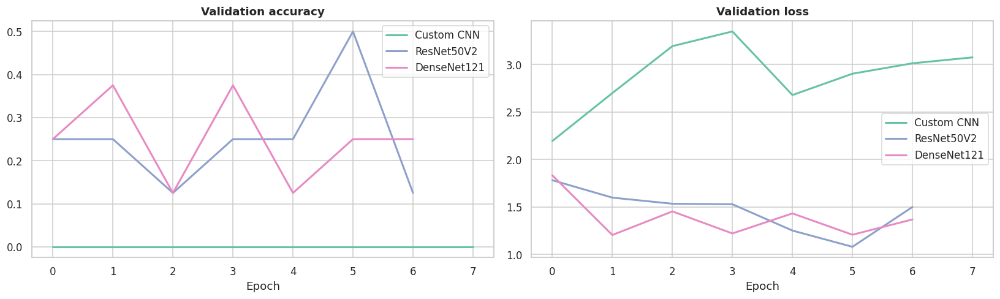

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for n in AVAILABLE:
    h = RESULTS[n]["history"]
    axes[0].plot(h["val_accuracy"], label=n, lw=2, color=palette[n])
    axes[1].plot(h["val_loss"], label=n, lw=2, color=palette[n])
axes[0].set_title("Validation accuracy"); axes[1].set_title("Validation loss")
for ax in axes: ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.show()

### 12.4 Per-class comparison
Which model handles which disease best? F1-score of every model on every class.

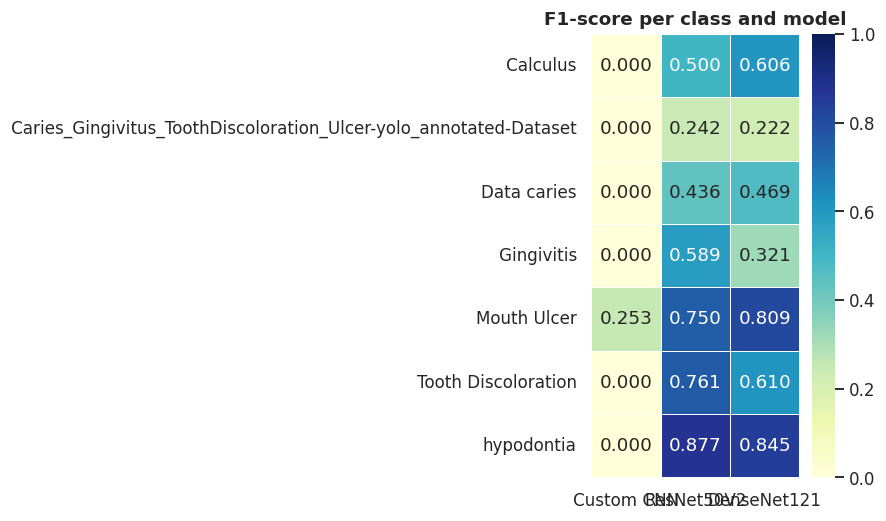

In [34]:
f1_table = pd.DataFrame({n: {c: RESULTS[n]["report"][c]["f1-score"] for c in CLASS_NAMES} for n in AVAILABLE})
plt.figure(figsize=(8, max(3.5, NUM_CLASSES * 0.7)))
sns.heatmap(f1_table, annot=True, fmt=".3f", cmap="YlGnBu", vmin=max(0, f1_table.values.min() - 0.05), vmax=1, linewidths=0.5)
plt.title("F1-score per class and model"); plt.ylabel(""); plt.tight_layout(); plt.show()

### 12.5 Discussion and conclusion of the comparison
Generated from the measured results: winner, improvement over the custom CNN, accuracy-versus-cost trade-off and the best model per class.

In [35]:
best = summary_df.iloc[0]
lines = [
    f"Winner: {best['Model']} with {best['Test Accuracy']*100:.2f}% test accuracy and macro F1 = {best['Macro F1']:.3f} (test set = {len(test_df)} images).",
    "Ranking by accuracy: " + " > ".join(f"{r['Model']} ({r['Test Accuracy']*100:.2f}%)" for _, r in summary_df.iterrows()) + ".",
]
cnn_rows, pre = summary_df[summary_df["Model"] == "Custom CNN"], summary_df[summary_df["Model"] != "Custom CNN"]
if len(cnn_rows) and len(pre):
    lines.append(f"Transfer learning vs. custom CNN: the best pretrained model ({pre.iloc[0]['Model']}) differs from the custom CNN by "
                 f"{(pre.iloc[0]['Test Accuracy'] - cnn_rows.iloc[0]['Test Accuracy'])*100:+.2f} accuracy points. Pretrained backbones start from rich ImageNet features "
                 f"(edges, textures, shapes), so they usually converge faster and generalise better on limited data.")
if len(summary_df) > 1:
    margin = summary_df.iloc[0]["Test Accuracy"] - summary_df.iloc[1]["Test Accuracy"]
    lines.append(f"Margin between first and second: {margin*100:.2f} points. " + ("This is small and may fall within sampling noise, so model size and speed should also influence the choice." if margin < 0.01 else "This is a clear lead."))
lines += [
    f"Efficiency: smallest model = {summary_df.loc[summary_df['Params (M)'].idxmin(), 'Model']} ({summary_df['Params (M)'].min():.2f}M parameters); fastest to train = {summary_df.loc[summary_df['Train Time (min)'].idxmin(), 'Model']} ({summary_df['Train Time (min)'].min():.1f} min).",
    f"Generalisation: the largest train-validation gap belongs to {summary_df.loc[summary_df['Train-Val Gap'].idxmax(), 'Model']} ({summary_df['Train-Val Gap'].max()*100:+.1f} points).",
    "Hardest classes overall: " + ", ".join(f1_table.mean(axis=1).sort_values().index[:2]) + " (lowest mean F1 across models).",
    "Best model per class: " + "; ".join(f"{c} -> {f1_table.loc[c].idxmax()}" for c in CLASS_NAMES) + ".",
]
if any(w.startswith("none") for w in summary_df["ImageNet Weights"]):
    lines.append("Note: at least one pretrained backbone had no ImageNet weights available and was trained from scratch; enable Internet or attach the weights for higher accuracy.")
print("\n".join(textwrap.fill(l, 130, subsequent_indent="    ", initial_indent="• ") for l in lines))

• Winner: ResNet50V2 with 61.07% test accuracy and macro F1 = 0.594 (test set = 262 images).
• Ranking by accuracy: ResNet50V2 (61.07%) > DenseNet121 (58.02%) > Custom CNN (14.50%).
• Transfer learning vs. custom CNN: the best pretrained model (ResNet50V2) differs from the custom CNN by +46.56 accuracy points.
    Pretrained backbones start from rich ImageNet features (edges, textures, shapes), so they usually converge faster and
    generalise better on limited data.
• Margin between first and second: 3.05 points. This is a clear lead.
• Efficiency: smallest model = Custom CNN (1.34M parameters); fastest to train = Custom CNN (0.6 min).
• Generalisation: the largest train-validation gap belongs to Custom CNN (+24.2 points).
• Hardest classes overall: Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset, Data caries (lowest mean F1 across
    models).
• Best model per class: Calculus -> DenseNet121; Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset -> ResNe

## 13. Deployment with Gradio
The best model (highest test accuracy, macro F1 as tie-breaker) is exported with everything needed to serve it:

```
deployment/
├── app.py              # Gradio application
├── best_model.keras    # full model (preprocessing included, augmentation off at inference)
├── app_config.json     # class names and image size
├── requirements.txt
├── README.md
└── examples/           # one test image per class
```
### 13.1 Export the best model and its artifacts

In [36]:
best_name = summary_df.iloc[0]["Model"]
print(f"Best model selected for deployment: {best_name}")
shutil.copy(RESULTS[best_name]["model_path"], DEPLOY_DIR / "best_model.keras")
(DEPLOY_DIR / "app_config.json").write_text(json.dumps({"model_name": best_name, "class_names": CLASS_NAMES, "img_size": list(IMG_SIZE)}, indent=2))

examples_dir = DEPLOY_DIR / "examples"; examples_dir.mkdir(exist_ok=True)
for cls in CLASS_NAMES:
    src = test_df.loc[test_df["label"] == cls, "path"].iloc[0]
    shutil.copy(src, examples_dir / f"{cls.replace(' ', '_')}{Path(src).suffix}")

(DEPLOY_DIR / "requirements.txt").write_text("tensorflow\nkeras\ngradio\nnumpy\npillow\n")
(DEPLOY_DIR / "README.md").write_text(
    f"# Oral Diseases Image Classifier\n\nGradio demo powered by **{best_name}**.\n\n"
    "```bash\npip install -r requirements.txt\npython app.py\n```\n\nEducational project - not a medical diagnostic tool.\n")
print("Artifacts written to:", DEPLOY_DIR)

Best model selected for deployment: ResNet50V2
Artifacts written to: /kaggle/working/deployment


### 13.2 Gradio application (`app.py`)
Loads the saved model, accepts an uploaded image and returns the top-3 predicted diseases with probabilities.

In [37]:
APP_CODE = textwrap.dedent("""
    import json
    from pathlib import Path

    import numpy as np
    import gradio as gr
    import keras
    from PIL import Image

    BASE = Path(__file__).resolve().parent
    CFG = json.loads((BASE / "app_config.json").read_text())
    CLASS_NAMES = CFG["class_names"]
    IMG_SIZE = tuple(CFG["img_size"])
    model = keras.models.load_model(str(BASE / "best_model.keras"), compile=False)


    def predict(image):
        if image is None:
            return {}
        img = image.convert("RGB").resize(IMG_SIZE)
        arr = np.asarray(img, dtype="float32")[None, ...]
        probs = model.predict(arr, verbose=0)[0]
        return {name: float(p) for name, p in zip(CLASS_NAMES, probs)}


    EXAMPLES = sorted(str(p) for p in (BASE / "examples").glob("*.*"))

    demo = gr.Interface(
        fn=predict,
        inputs=gr.Image(type="pil", label="Upload an oral image"),
        outputs=gr.Label(num_top_classes=3, label="Predicted condition"),
        title="Oral Diseases Image Classifier",
        description="Model: " + CFG["model_name"] + ". Upload a photo to get the top-3 predictions. "
                    "For educational purposes only - not a medical diagnosis.",
        examples=EXAMPLES or None,
        cache_examples=False,
    )

    if __name__ == "__main__":
        demo.launch()
""").strip() + "\n"

(DEPLOY_DIR / "app.py").write_text(APP_CODE)
print(APP_CODE)

import json
from pathlib import Path

import numpy as np
import gradio as gr
import keras
from PIL import Image

BASE = Path(__file__).resolve().parent
CFG = json.loads((BASE / "app_config.json").read_text())
CLASS_NAMES = CFG["class_names"]
IMG_SIZE = tuple(CFG["img_size"])
model = keras.models.load_model(str(BASE / "best_model.keras"), compile=False)


def predict(image):
    if image is None:
        return {}
    img = image.convert("RGB").resize(IMG_SIZE)
    arr = np.asarray(img, dtype="float32")[None, ...]
    probs = model.predict(arr, verbose=0)[0]
    return {name: float(p) for name, p in zip(CLASS_NAMES, probs)}


EXAMPLES = sorted(str(p) for p in (BASE / "examples").glob("*.*"))

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil", label="Upload an oral image"),
    outputs=gr.Label(num_top_classes=3, label="Predicted condition"),
    title="Oral Diseases Image Classifier",
    description="Model: " + CFG["model_name"] + ". Upload a photo to get the top-3 pr

### 13.3 Verify that the exported model matches the evaluated model
Reload `best_model.keras` from disk and compare its predictions with the probabilities stored during evaluation — this guarantees that the deployed app behaves exactly like the model that was tested.

In [38]:
reloaded = keras.models.load_model(str(DEPLOY_DIR / "best_model.keras"), compile=False)
batch_x, _ = next(iter(test_ds))
p_disk = reloaded.predict(batch_x, verbose=0)
p_ref = RESULTS[best_name]["probs"][:len(p_disk)]
print("Max absolute difference between probabilities:", float(np.abs(p_ref - p_disk).max()))
print("Identical class predictions:", bool((p_ref.argmax(1) == p_disk.argmax(1)).all()))
del reloaded; keras.backend.clear_session(); gc.collect();

Max absolute difference between probabilities: 0.0
Identical class predictions: True


### 13.4 Launch the Gradio app
Imports the generated `app.py` (so the notebook tests the real deliverable) and launches it. With Internet on, a public `*.gradio.live` link is created; otherwise the app runs locally inside the notebook. Any Gradio problem is reported without stopping the notebook.

### 13.5 Package the deployment folder
Creates `deployment.zip` in the output panel — ready to download or upload as a **Hugging Face Space** (SDK: Gradio) for a permanent public link.

In [40]:
archive = shutil.make_archive(str(WORK_DIR / "deployment"), "zip", DEPLOY_DIR)
print("Deployment package:", archive, f"({os.path.getsize(archive)/1e6:.1f} MB)")

Deployment package: /kaggle/working/deployment.zip (221.6 MB)
Created dataset file at: .gradio/flagged/dataset1.csv


In [39]:
try:
    try:
        import gradio as gr
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
        import gradio as gr
    import importlib
    sys.path.insert(0, str(DEPLOY_DIR))
    app_module = importlib.import_module("app")
    try:
        app_module.demo.launch(share=True, prevent_thread_lock=True)
    except Exception:
        app_module.demo.launch(share=False, prevent_thread_lock=True)
except Exception as e:
    print(f"Gradio could not be launched here ({type(e).__name__}: {e}).")
    print(f"The full app is still exported in {DEPLOY_DIR}: run 'python app.py' there or upload the folder to a Hugging Face Space.")

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://f9d092fee8d0fc9e76.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 14. Final Conclusions, Limitations and Future Work
**Summary**
* A custom CNN and three ImageNet-pretrained models (EfficientNetB0, ResNet50V2, DenseNet121) were trained on identical data with augmentation, automatic hyperparameter search, learning-rate scheduling, best-weights checkpointing, early stopping and fine-tuning, then compared on an untouched test set (Section 12).
* The best model was exported and deployed as a Gradio application (Section 13).

**Limitations**
* This fast edition trains on a small sample (≤ 250 images per class) at 160×160 with very short training, so accuracy is lower than the full notebook and class-level results are noisy.
* Some datasets contain augmented copies of the same photo; if copies end up on both sides of a random split, test accuracy can be optimistic. Use an independent test set for a final clinical-style claim.
* Visually similar diseases are the main source of errors (see the confusion matrices); results on a small test set are noisy.
* This is an educational prototype and **not** a medical diagnostic device.

**Future work**
* Larger / newer backbones (EfficientNetV2, ConvNeXt, ViT) and ensembling the top models.
* Test-time augmentation, probability calibration and Grad-CAM explanations.
* More data for the hardest classes, and cross-validation for tighter confidence intervals.